## Setup

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from google.colab import files

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

## 1. Load the processed data

In [ ]:
# 1. LOAD THE PROCESSED DATA
# (the three split files from the preprocessing notebook)

base_url = "https://raw.githubusercontent.com/Group-22-AI-ML/medical-diagnosis-network/main/Model/Preprocessing/"

train = pd.read_csv(base_url + "train.csv")
val = pd.read_csv(base_url + "validation.csv")
test = pd.read_csv(base_url + "test.csv")

X_train = train.drop("class", axis=1)
y_train = train["class"].values

X_val = val.drop("class", axis=1)
y_val = val["class"].values

X_test = test.drop("class", axis=1)
y_test = test["class"].values

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Xtr, Xva, Xte = (d.values.astype("float32") for d in (X_train, X_val, X_test))

Train: (364, 9)
Validation: (78, 9)
Test: (78, 9)


## 2. Architecture

In [ ]:
# ARCHITECTURE
model = keras.Sequential([
    layers.Input(shape=(Xtr.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
], name="baseline_mlp")

## 3. Training settings and training

In [ ]:
# TRAINING SETTINGS
LOSS, LR, BATCH_SIZE, MAX_EPOCHS, PATIENCE = "binary_crossentropy", 0.001, 32, 300, 15
model.compile(loss=LOSS, optimizer=keras.optimizers.Adam(learning_rate=LR), metrics=["accuracy"])
model.summary()

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
history = model.fit(Xtr, y_train, validation_data=(Xva, y_val),
                    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, callbacks=[early_stop], verbose=0)
epochs_run = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nStopped after {epochs_run} epochs; best epoch = {best_epoch}")

Model: "baseline_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)


Stopped after 61 epochs; best epoch = 46


## 4. Evaluation (test set)


Accuracy : 0.9231
Precision: 0.9130
Recall   : 0.9545
F1-score : 0.9333

                  precision    recall  f1-score   support

No diabetes (0)       0.94      0.88      0.91        34
   Diabetes (1)       0.91      0.95      0.93        44

       accuracy                           0.92        78
      macro avg       0.93      0.92      0.92        78
   weighted avg       0.92      0.92      0.92        78



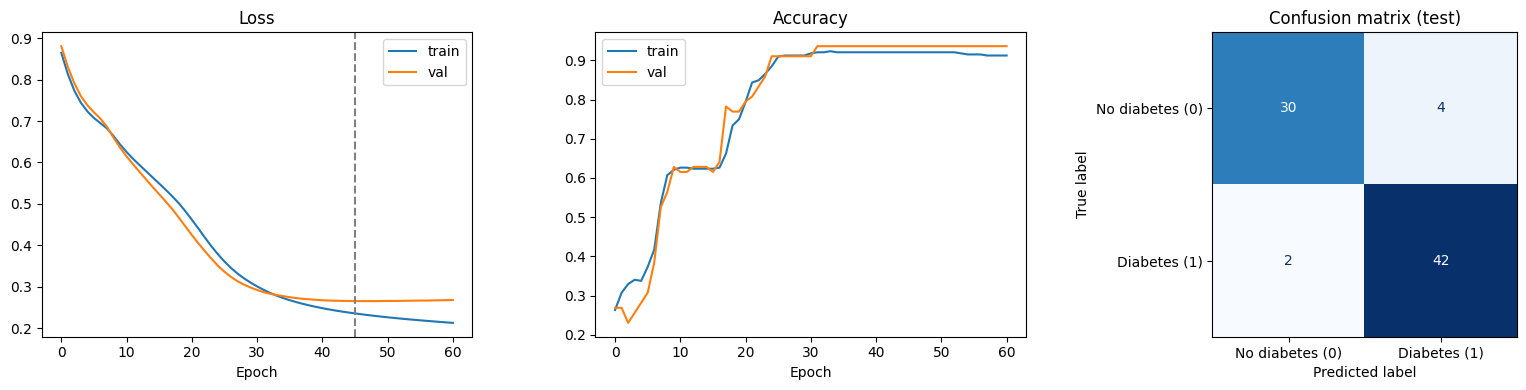

In [ ]:
# EVALUATION (test set, threshold 0.5)

pred = (model.predict(Xte, verbose=0).ravel() >= 0.5).astype(int)
acc  = accuracy_score(y_test, pred)
prec = precision_score(y_test, pred, zero_division=0)
rec  = recall_score(y_test, pred, zero_division=0)
f1   = f1_score(y_test, pred, zero_division=0)
cm   = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()

print(f"\nAccuracy : {acc:.4f}\nPrecision: {prec:.4f}\nRecall   : {rec:.4f}\nF1-score : {f1:.4f}")
print("\n", classification_report(y_test, pred, target_names=["No diabetes (0)", "Diabetes (1)"], zero_division=0))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].axvline(best_epoch - 1, ls="--", c="gray"); ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
ConfusionMatrixDisplay(cm, display_labels=["No diabetes (0)", "Diabetes (1)"]).plot(
    ax=ax[2], cmap="Blues", values_format="d", colorbar=False)
ax[2].set_title("Confusion matrix (test)")
plt.tight_layout(); plt.savefig("baseline_plots.png", dpi=150); plt.show()

In [ ]:
# 5. SUMMARY

summary = f"""BASELINE NEURAL NETWORK - SUMMARY

ARCHITECTURE
  Input({Xtr.shape[1]}) -> Dense(16, ReLU) -> Dense(8, ReLU) -> Dense(1, Sigmoid)   [{model.count_params()} parameters]

TRAINING SETTINGS
  Loss      : {LOSS}
  Optimizer : Adam (learning rate {LR})
  Batch size: {BATCH_SIZE}
  Epochs    : up to {MAX_EPOCHS}, early stopping on val_loss (patience {PATIENCE}, best weights restored)
              -> stopped at epoch {epochs_run}, best epoch {best_epoch}
  Seed      : {SEED}
  Data split: train {len(y_train)} / val {len(y_val)} / test {len(y_test)}

TEST RESULTS (threshold 0.5)
  Accuracy  : {acc:.4f}
  Precision : {prec:.4f}
  Recall    : {rec:.4f}
  F1-score  : {f1:.4f}
  Confusion matrix:  TN={tn}  FP={fp}  FN={fn}  TP={tp}
"""
print(summary)
open("baseline_summary.txt", "w").write(summary)
model.save("baseline_model.keras")

# Download files
files.download("baseline_summary.txt")
files.download("baseline_model.keras")

print("files downloaded successfully ")

BASELINE NEURAL NETWORK - SUMMARY

ARCHITECTURE
  Input(9) -> Dense(16, ReLU) -> Dense(8, ReLU) -> Dense(1, Sigmoid)   [305 parameters]

TRAINING SETTINGS
  Loss      : binary_crossentropy
  Optimizer : Adam (learning rate 0.001)
  Batch size: 32
  Epochs    : up to 300, early stopping on val_loss (patience 15, best weights restored)
              -> stopped at epoch 61, best epoch 46
  Seed      : 42
  Data split: train 364 / val 78 / test 78

TEST RESULTS (threshold 0.5)
  Accuracy  : 0.9231
  Precision : 0.9130
  Recall    : 0.9545
  F1-score  : 0.9333
  Confusion matrix:  TN=30  FP=4  FN=2  TP=42



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

files downloaded successfully 
